# 1. Linear, Interaction and Polynomial Regression

**Question.** A factory wants to know how air temperature and humidity affect machine performance (a positive, continuous score where higher is better). Which model describes the relationship best, and which variable matters more?

**Data.** 200 observations of temperature, humidity and machine performance (`data/machine_performance.csv`). The data is synthetic, provided for a university course.

**Approach.** Split 70% train / 30% test, fit three models of increasing complexity, check the regression assumptions, and choose by AIC, BIC and test error.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
DATA = Path("../data"); FIG = Path("../images"); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
})
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv(DATA / "machine_performance.csv")
train, test = train_test_split(df, test_size=0.3, random_state=42)
print(f"{len(df)} rows | train {len(train)} | test {len(test)}")
df.describe().round(2)

200 rows | train 140 | test 60


,temperature,humidity,performance
count,200.00,200.00,200.00
mean,17.71,24.67,383.07
std,11.81,14.69,283.34
min,0.01,0.21,7.12
25%,6.80,10.87,143.40
50%,16.28,24.14,335.45
75%,27.86,38.26,569.37
max,39.58,49.54,1222.59


## 1.1 Fit three models

All models are fitted on the training set only and evaluated on the test set.

In [2]:
FORMULAS = {
    "Linear": "performance ~ temperature + humidity",
    "Interaction": "performance ~ temperature * humidity",
    "Polynomial (degree 2)": "performance ~ temperature * humidity + I(temperature**2) + I(humidity**2)",
}
models, rows = {}, []
for name, f in FORMULAS.items():
    m = smf.ols(f, train).fit()
    pred = m.predict(test)
    rmse = np.sqrt(((test.performance - pred) ** 2).mean())
    r2_test = 1 - ((test.performance - pred) ** 2).sum() / ((test.performance - test.performance.mean()) ** 2).sum()
    bp_p = het_breuschpagan(m.resid, m.model.exog)[1]
    models[name] = m
    rows.append({"model": name, "parameters": int(m.df_model) + 1, "R² (train)": m.rsquared, "AIC": m.aic, "BIC": m.bic,
                 "RMSE (test)": rmse, "R² (test)": r2_test, "Breusch-Pagan p": bp_p})
comparison = pd.DataFrame(rows).set_index("model")
comparison.style.format({"R² (train)": "{:.4f}", "R² (test)": "{:.4f}", "AIC": "{:.0f}", "BIC": "{:.0f}",
                         "RMSE (test)": "{:.1f}", "Breusch-Pagan p": "{:.3f}"})

,parameters,R² (train),AIC,BIC,RMSE (test),R² (test),Breusch-Pagan p
model,,,,,,,
Linear,3,0.9226,1628,1637,76.8,0.9181,0.013
Interaction,4,0.9917,1318,1330,28.2,0.9890,0.331
Polynomial (degree 2),6,0.9999,703,721,2.8,0.9999,0.696


**Reading.** Each step up in complexity improves every measure. Test RMSE falls from 76.8 to 28.2 with the interaction term, and to 2.8 with the full quadratic model. AIC and BIC agree, so the gain is not just extra parameters.

A test R² of 0.9999 would be suspicious in real data. Here it means the course dataset was generated from a quadratic function with small noise, and the degree-2 model recovers that function almost exactly.

### Is degree 2 enough?

Full polynomials of degree 1 to 5 in both variables, all terms and interactions included.

In [3]:
from sklearn.preprocessing import PolynomialFeatures
rows = []
for d in range(1, 6):
    poly = PolynomialFeatures(d)
    m = sm.OLS(train.performance, poly.fit_transform(train[["temperature", "humidity"]])).fit()
    pred = m.predict(poly.transform(test[["temperature", "humidity"]]))
    rows.append({"degree": d, "parameters": m.model.exog.shape[1], "AIC": m.aic, "BIC": m.bic,
                 "RMSE (test)": np.sqrt(((test.performance - pred) ** 2).mean())})
degrees = pd.DataFrame(rows).set_index("degree")
degrees.style.format({"AIC": "{:.0f}", "BIC": "{:.0f}", "RMSE (test)": "{:.2f}"})

,parameters,AIC,BIC,RMSE (test)
degree,,,,
1,3,1628,1637,76.79
2,6,703,721,2.85
3,10,706,736,2.94
4,15,712,756,2.99
5,21,719,781,3.06


AIC, BIC and test RMSE are all lowest at degree 2. Higher degrees add parameters without improving the fit, which is the usual sign of overfitting.

## 1.2 Assumption checks

The residual plots below show why the simpler models fall short.

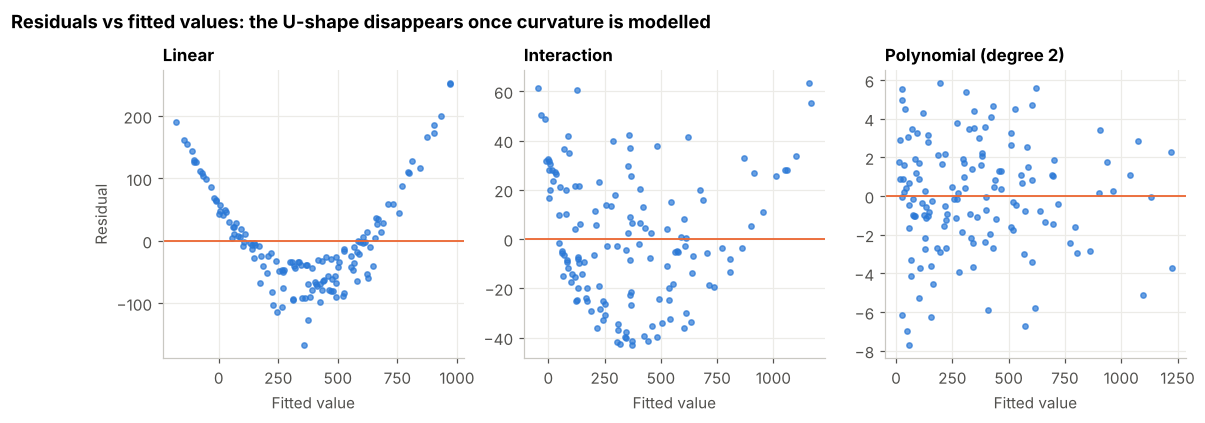

Durbin-Watson (linear): 2.21
VIF (linear): {'temperature': np.float64(1.01), 'humidity': np.float64(1.01)}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
for ax, (name, m) in zip(axes, models.items()):
    ax.scatter(m.fittedvalues, m.resid, s=12, color=BLUE, alpha=0.7)
    ax.axhline(0, color=ORANGE, lw=1.2)
    ax.set(title=name, xlabel="Fitted value")
axes[0].set_ylabel("Residual")
fig.suptitle("Residuals vs fitted values: the U-shape disappears once curvature is modelled", x=0.01, y=1.04, ha="left", fontweight="bold")
fig.savefig(FIG / "01_residuals_by_model.png"); plt.show()

lin = models["Linear"]
X = lin.model.exog
print("Durbin-Watson (linear):", round(durbin_watson(lin.resid), 2))
print("VIF (linear):", {lin.model.exog_names[i]: round(variance_inflation_factor(X, i), 2) for i in range(1, X.shape[1])})

**Reading.**

- **Linearity.** The linear model's residuals form a clear U-shape, so the relationship is not linear.
- **Constant variance.** Breusch-Pagan rejects constant variance for the linear model (p = 0.013) but not for the polynomial model (p = 0.70). The apparent heteroscedasticity was a symptom of the wrong functional form, not a separate problem, so no robust standard errors are needed once the model is right.
- **Independence and collinearity.** Durbin-Watson is close to 2 and VIFs are close to 1, so neither is a concern.

## 1.3 Interpreting the interaction

In the interaction model the effect of humidity depends on temperature:

$$\frac{\partial \hat{Y}}{\partial H} = \beta_H + \beta_{TH} \cdot T$$

In [5]:
p = models["Interaction"].params
for T in [10, 20, 30]:
    print(f"Temperature {T}: +1 humidity changes performance by {p['humidity'] + p['temperature:humidity'] * T:.2f}")

Temperature 10: +1 humidity changes performance by 12.07
Temperature 20: +1 humidity changes performance by 16.52
Temperature 30: +1 humidity changes performance by 20.96


At a temperature of 10, one extra unit of humidity raises performance by about 12.1. At 30 the same unit adds about 21, so humidity matters more in warm conditions.

## 1.4 Which variable matters more?

In the polynomial model the effect of each variable changes across the range, so it is measured as the change in predicted performance when the variable rises by one standard deviation from the training means.

In [6]:
best = models["Polynomial (degree 2)"]
base = pd.DataFrame({"temperature": [train.temperature.mean()], "humidity": [train.humidity.mean()]})
effects = {}
for var in ["temperature", "humidity"]:
    up = base.copy(); up[var] += train[var].std()
    effects[var] = float(best.predict(up).iloc[0] - best.predict(base).iloc[0])
print({k: round(v, 1) for k, v in effects.items()})

{'temperature': 188.6, 'humidity': 255.2}


**Reading.** A one-standard-deviation increase in humidity raises predicted performance by more than the same increase in temperature, so humidity has the larger effect at typical conditions.

## Summary

| Model | Test RMSE | AIC | Verdict |
|---|---|---|---|
| Linear | 76.8 | 1,628 | Misses curvature; residuals show a U-shape |
| Interaction | 28.2 | 1,318 | Captures that humidity matters more when it is warm |
| Polynomial (degree 2) | 2.8 | 703 | Best on every measure; assumptions hold |

The degree-2 polynomial is the final model.